In [1]:
# --- 1. Imports ---
import os
import shutil
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetV2B0
from tensorflow.keras.preprocessing import image_dataset_from_directory
from sklearn.metrics import classification_report
from tqdm.notebook import tqdm

In [18]:
# --- 1. Mount Google Drive ---
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [6]:
!pip install quickdraw
from quickdraw import QuickDrawDataGroup
import os

# List of categories
categories = [
    "aircraft carrier",
    "airplane",
    "alarm clock",
    "ambulance",
    "angel",
    "animal migration",
    "ant",
    "anvil",
    "apple",
    "arm",
    "asparagus",
    "axe",
    "backpack",
    "banana",
    "bandage",
    "barn",
    "baseball",
    "baseball bat",
    "basket",
    "basketball",
    "bat",
    "bathtub",
    "beach",
    "bear",
    "beard",
    "bed",
    "bee",
    "belt",
    "bench",
    "bicycle",
    "binoculars",
    "bird",
    "birthday cake",
    "blackberry",
    "blueberry",
    "book",
    "boomerang",
    "bottlecap",
    "bowtie",
    "bracelet",
    "brain",
    "bread",
    "bridge",
    "broccoli",
    "broom",
    "bucket",
    "bulldozer",
    "bus",
    "bush",
    "butterfly",
    "cactus",
    "cake",
    "calculator",
    "calendar",
    "camel",
    "camera",
    "camouflage",
    "campfire",
    "candle",
    "cannon",
    "canoe",
    "car",
    "carrot",
    "castle",
    "cat",
    "ceiling fan",
    "cello",
    "cell phone",
    "chair",
    "chandelier",
    "church",
    "circle",
    "clarinet",
    "clock",
    "cloud",
    "coffee cup",
    "compass",
    "computer",
    "cookie",
    "cooler",
    "couch",
    "cow",
    "crab",
    "crayon",
    "crocodile",
    "crown",
    "cruise ship",
    "cup",
    "diamond",
    "dishwasher",
    "diving board",
    "dog",
    "dolphin",
    "donut",
    "door",
    "dragon",
    "dresser",
    "drill",
    "drums",
    "duck",
    "dumbbell",
    "ear",
    "elbow",
    "elephant",
    "envelope",
    "eraser",
    "eye",
    "eyeglasses",
    "face",
    "fan",
    "feather",
    "fence",
    "finger",
    "fire hydrant",
    "fireplace",
    "firetruck",
    "fish",
    "flamingo",
    "flashlight",
    "flip flops",
    "floor lamp",
    "flower",
    "flying saucer",
    "foot",
    "fork",
    "frog",
    "frying pan",
    "garden",
    "garden hose",
    "giraffe",
    "goatee",
    "golf club",
    "grapes",
    "grass",
    "guitar",
    "hamburger",
    "hammer",
    "hand",
    "harp",
    "hat",
    "headphones",
    "hedgehog",
    "helicopter",
    "helmet",
    "hexagon",
    "hockey puck",
    "hockey stick",
    "horse",
    "hospital",
    "hot air balloon",
    "hot dog",
    "hot tub",
    "hourglass",
    "house",
    "house plant",
    "hurricane",
    "ice cream",
    "jacket",
    "jail",
    "kangaroo",
    "key",
    "keyboard",
    "knee",
    "knife",
    "ladder",
    "lantern",
    "laptop",
    "leaf",
    "leg",
    "light bulb",
    "lighter",
    "lighthouse",
    "lightning",
    "line",
    "lion",
    "lipstick",
    "lobster",
    "lollipop",
    "mailbox",
    "map",
    "marker",
    "matches",
    "megaphone",
    "mermaid",
    "microphone",
    "microwave",
    "monkey",
    "moon",
    "mosquito",
    "motorbike",
    "mountain",
    "mouse",
    "moustache",
    "mouth",
    "mug",
    "mushroom",
    "nail",
    "necklace",
    "nose",
    "ocean",
    "octagon",
    "octopus",
    "onion",
    "oven",
    "owl",
    "paintbrush",
    "paint can",
    "palm tree",
    "panda",
    "pants",
    "paper clip",
    "parachute",
    "parrot",
    "passport",
    "peanut",
    "pear",
    "peas",
    "pencil",
    "penguin",
    "piano",
    "pickup truck",
    "picture frame",
    "pig",
    "pillow",
    "pineapple",
    "pizza",
    "pliers",
    "police car",
    "pond",
    "pool",
    "popsicle",
    "postcard",
    "potato",
    "power outlet",
    "purse",
    "rabbit",
    "raccoon",
    "radio",
    "rain",
    "rainbow",
    "rake",
    "remote control",
    "rhinoceros",
    "rifle",
    "river",
    "roller coaster",
    "rollerskates",
    "sailboat",
    "sandwich",
    "saw",
    "saxophone",
    "school bus",
    "scissors",
    "scorpion",
    "screwdriver",
    "sea turtle",
    "see saw",
    "shark",
    "sheep",
    "shoe",
    "shorts",
    "shovel",
    "sink",
    "skateboard",
    "skull",
    "skyscraper",
    "sleeping bag",
    "smiley face",
    "snail",
    "snake",
    "snorkel",
    "snowflake",
    "snowman",
    "soccer ball",
    "sock",
    "speedboat",
    "spider",
    "spoon",
    "spreadsheet",
    "square",
    "squiggle",
    "squirrel",
    "stairs",
    "star",
    "steak",
    "stereo",
    "stethoscope",
    "stitches",
    "stop sign",
    "stove",
    "strawberry",
    "streetlight",
    "string bean",
    "submarine",
    "suitcase",
    "sun",
    "swan",
    "sweater",
    "swing set",
    "sword",
    "syringe",
    "table",
    "teapot",
    "teddy-bear",
    "telephone",
    "television",
    "tennis racquet",
    "tent",
    "The Eiffel Tower",
    "The Great Wall of China",
    "The Mona Lisa",
    "tiger",
    "toaster",
    "toe",
    "toilet",
    "tooth",
    "toothbrush",
    "toothpaste",
    "tornado",
    "tractor",
    "traffic light",
    "train",
    "tree",
    "triangle",
    "trombone",
    "truck",
    "trumpet",
    "t-shirt",
    "umbrella",
    "underwear",
    "van",
    "vase",
    "violin",
    "washing machine",
    "watermelon",
    "waterslide",
    "whale",
    "wheel",
    "windmill",
    "wine bottle",
    "wine glass",
    "wristwatch",
    "yoga",
    "zebra",
    "zigzag"
]
# or however many you want

for category in categories:
    os.makedirs(category, exist_ok=True)
    qdg = QuickDrawDataGroup(category, recognized=True, max_drawings=1000)
    for i, drawing in enumerate(qdg.drawings):
        drawing.image.save(f"{category}/{category}_{i}.png")


downloading aircraft carrier from https://storage.googleapis.com/quickdraw_dataset/full/binary/aircraft carrier.bin
download complete
loading aircraft carrier drawings
load complete
loading airplane drawings
load complete
downloading alarm clock from https://storage.googleapis.com/quickdraw_dataset/full/binary/alarm clock.bin
download complete
loading alarm clock drawings
load complete
downloading ambulance from https://storage.googleapis.com/quickdraw_dataset/full/binary/ambulance.bin
download complete
loading ambulance drawings
load complete
downloading angel from https://storage.googleapis.com/quickdraw_dataset/full/binary/angel.bin
download complete
loading angel drawings
load complete
downloading animal migration from https://storage.googleapis.com/quickdraw_dataset/full/binary/animal migration.bin
download complete
loading animal migration drawings
load complete
downloading ant from https://storage.googleapis.com/quickdraw_dataset/full/binary/ant.bin
download complete
loading ant

In [19]:
import os
import shutil
import random

# --- 3. Paths & Setup ---
SOURCE_DIR = "/content"  # dataset with category folders
DEST_DIR = "/content/small_data"
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
split_ratio = [0.6, 0.2, 0.2]  # train/val/test
MAX_PER_CLASS = 1000
SAMPLE_FROM_EACH = int(MAX_PER_CLASS * 0.2)  # 20% = 200 images/class
os.makedirs(DEST_DIR, exist_ok=True)

# --- 4. Create Subset of 200 Images/Class ---
categories = [d for d in os.listdir(SOURCE_DIR) if os.path.isdir(os.path.join(SOURCE_DIR, d))]

for cat in categories:
    full_path = os.path.join(SOURCE_DIR, cat)
    images = [f for f in os.listdir(full_path) if f.endswith(".png")]

    if len(images) < 10:
        continue

    images = images[:MAX_PER_CLASS] if len(images) > MAX_PER_CLASS else images
    sampled_images = random.sample(images, SAMPLE_FROM_EACH)

    train_split = int(SAMPLE_FROM_EACH * split_ratio[0])
    val_split = int(SAMPLE_FROM_EACH * split_ratio[1])
    train_imgs = sampled_images[:train_split]
    val_imgs = sampled_images[train_split:train_split+val_split]
    test_imgs = sampled_images[train_split+val_split:]

    for split, split_imgs in zip(["train", "val", "test"], [train_imgs, val_imgs, test_imgs]):
        split_cat_path = os.path.join(DEST_DIR, split, cat)
        os.makedirs(split_cat_path, exist_ok=True)
        for img_name in split_imgs:
            shutil.copy(os.path.join(full_path, img_name), os.path.join(split_cat_path, img_name))

print("✅ Subset created at:", DEST_DIR)


✅ Subset created at: /content/small_data


In [20]:
# --- 5. Load Datasets ---
train_ds = image_dataset_from_directory(f"{DEST_DIR}/train", image_size=IMAGE_SIZE, batch_size=BATCH_SIZE)
val_ds   = image_dataset_from_directory(f"{DEST_DIR}/val",   image_size=IMAGE_SIZE, batch_size=BATCH_SIZE)
test_ds  = image_dataset_from_directory(f"{DEST_DIR}/test",  image_size=IMAGE_SIZE, batch_size=BATCH_SIZE)

class_names = train_ds.class_names
num_classes = len(class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds   = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds  = test_ds.prefetch(buffer_size=AUTOTUNE)


Found 206241 files belonging to 345 classes.
Found 77912 files belonging to 345 classes.
Found 77976 files belonging to 345 classes.


In [21]:
# --- 6. Data Augmentation ---
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
])


In [14]:
# --- 6. ProgressBar Callback ---
class TQDMProgressBar(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.epochs = self.params['epochs']
        self.progbar = tqdm(total=self.epochs, desc="Training", unit="epoch")
    def on_epoch_end(self, epoch, logs=None):
        self.progbar.update(1)
        metrics = ', '.join([f"{k}: {v:.4f}" for k, v in logs.items()])
        self.progbar.set_postfix_str(metrics)
    def on_train_end(self, logs=None):
        self.progbar.close()

In [22]:
# --- 7. Custom Callbacks ---
class TQDMProgressBar(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.epochs = self.params['epochs']
        self.progbar = tqdm(total=self.epochs, desc="Training", unit="epoch")
    def on_epoch_end(self, epoch, logs=None):
        self.progbar.update(1)
        metrics = ', '.join([f"{k}: {v:.4f}" for k, v in logs.items()])
        self.progbar.set_postfix_str(metrics)
    def on_train_end(self, logs=None):
        self.progbar.close()

# Save every 3 epochs to Google Drive
class EpochSaver(tf.keras.callbacks.Callback):
    def __init__(self, save_every=3, save_path="/content/drive/MyDrive/efficientnet_checkpoints"):
        super().__init__()
        self.save_every = save_every
        self.save_path = save_path
        os.makedirs(self.save_path, exist_ok=True)
    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.save_every == 0:
            filename = f"model_epoch_{epoch+1:03d}.h5"
            full_path = os.path.join(self.save_path, filename)
            self.model.save(full_path)
            print(f"📦 Saved checkpoint to Google Drive: {full_path}")

checkpoint_cb = EpochSaver(save_every=3)


In [23]:
# --- 8. Build EfficientNetV2B0 Model ---
base_model = EfficientNetV2B0(include_top=False, input_shape=(224, 224, 3), weights='imagenet')
base_model.trainable = False

model = models.Sequential([
    data_augmentation,
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-b0 (Functional)  │ (None, 7, 7, 1280)     │     5,919,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ ?                      │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,919,312 (22.58 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 5,919,312 (22.58 MB)

Above shows the model before training. 

In [24]:
# --- 9. Phase 1: Train Top Layers (10 Epochs) ---
initial_epochs = 10
history = model.fit(train_ds, validation_data=val_ds, epochs=initial_epochs,
                    callbacks=[TQDMProgressBar(), checkpoint_cb])

Training:   0%|          | 0/10 [00:00<?, ?epoch/s]

Epoch 1/10
6446/6446 ━━━━━━━━━━━━━━━━━━━━ 174s 25ms/step - accuracy: 0.1305 - loss: 4.2480 - val_accuracy: 0.3580 - val_loss: 2.6439
Epoch 2/10
6446/6446 ━━━━━━━━━━━━━━━━━━━━ 158s 25ms/step - accuracy: 0.2661 - loss: 3.1824 - val_accuracy: 0.3893 - val_loss: 2.4824
Epoch 3/10
6446/6446 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.2907 - loss: 3.0467

📦 Saved checkpoint to Google Drive: /content/drive/MyDrive/efficientnet_checkpoints/model_epoch_003.h5
6446/6446 ━━━━━━━━━━━━━━━━━━━━ 159s 25ms/step - accuracy: 0.2907 - loss: 3.0467 - val_accuracy: 0.4110 - val_loss: 2.3765
Epoch 4/10
6446/6446 ━━━━━━━━━━━━━━━━━━━━ 158s 25ms/step - accuracy: 0.3013 - loss: 2.9826 - val_accuracy: 0.4225 - val_loss: 2.3220
Epoch 5/10
6446/6446 ━━━━━━━━━━━━━━━━━━━━ 159s 25ms/step - accuracy: 0.3099 - loss: 2.9400 - val_accuracy: 0.4219 - val_loss: 2.3270
Epoch 6/10
6445/6446 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.3136 - loss: 2.9188

📦 Saved checkpoint to Google Drive: /content/drive/MyDrive/efficientnet_checkpoints/model_epoch_006.h5
6446/6446 ━━━━━━━━━━━━━━━━━━━━ 159s 25ms/step - accuracy: 0.3136 - loss: 2.9188 - val_accuracy: 0.4226 - val_loss: 2.3192
Epoch 7/10
6446/6446 ━━━━━━━━━━━━━━━━━━━━ 158s 25ms/step - accuracy: 0.3167 - loss: 2.8996 - val_accuracy: 0.4291 - val_loss: 2.2957
Epoch 8/10
6446/6446 ━━━━━━━━━━━━━━━━━━━━ 160s 25ms/step - accuracy: 0.3199 - loss: 2.8826 - val_accuracy: 0.4409 - val_loss: 2.2280
Epoch 9/10
6445/6446 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.3219 - loss: 2.8697

📦 Saved checkpoint to Google Drive: /content/drive/MyDrive/efficientnet_checkpoints/model_epoch_009.h5
6446/6446 ━━━━━━━━━━━━━━━━━━━━ 159s 25ms/step - accuracy: 0.3219 - loss: 2.8697 - val_accuracy: 0.4424 - val_loss: 2.2224
Epoch 10/10
6446/6446 ━━━━━━━━━━━━━━━━━━━━ 160s 25ms/step - accuracy: 0.3254 - loss: 2.8646 - val_accuracy: 0.4342 - val_loss: 2.2578


In [25]:
# --- 9. Phase 2: Fine-Tune Entire Model ---
base_model.trainable = True
model.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

fine_tune_epochs = 40  # now run 40 fine-tune epochs to reach 50 total
total_epochs = initial_epochs + fine_tune_epochs
history_fine = model.fit(train_ds, validation_data=val_ds, initial_epoch=initial_epochs, epochs=total_epochs, callbacks=[TQDMProgressBar(), checkpoint_cb])

Training:   0%|          | 0/50 [00:00<?, ?epoch/s]

Epoch 11/50
6446/6446 ━━━━━━━━━━━━━━━━━━━━ 692s 100ms/step - accuracy: 0.1562 - loss: 4.7718 - val_accuracy: 0.4883 - val_loss: 2.0086
Epoch 12/50
6446/6446 ━━━━━━━━━━━━━━━━━━━━ 639s 99ms/step - accuracy: 0.3619 - loss: 2.6342 - val_accuracy: 0.5496 - val_loss: 1.7310
Epoch 13/50
6446/6446 ━━━━━━━━━━━━━━━━━━━━ 639s 99ms/step - accuracy: 0.4120 - loss: 2.3850 - val_accuracy: 0.5812 - val_loss: 1.5954
Epoch 14/50
6446/6446 ━━━━━━━━━━━━━━━━━━━━ 638s 99ms/step - accuracy: 0.4398 - loss: 2.2364 - val_accuracy: 0.5998 - val_loss: 1.5150
Epoch 15/50
6446/6446 ━━━━━━━━━━━━━━━━━━━━ 640s 99ms/step - accuracy: 0.4593 - loss: 2.1444 - val_accuracy: 0.6100 - val_loss: 1.4635
Epoch 16/50
6446/6446 ━━━━━━━━━━━━━━━━━━━━ 639s 99ms/step - accuracy: 0.4779 - loss: 2.0663 - val_accuracy: 0.6266 - val_loss: 1.3904
Epoch 17/50
6446/6446 ━━━━━━━━━━━━━━━━━━━━ 639s 99ms/step - accuracy: 0.4911 - loss: 2.0034 - val_accuracy: 0.6359 - val_loss: 1.3487
Epoch 18/50
6446/6446 ━━━━━━━━━━━━━━━━━━━━ 639s 99ms/step - a

In [26]:
# --- 11. Evaluate on Test Set ---
model.evaluate(test_ds)

2437/2437 ━━━━━━━━━━━━━━━━━━━━ 37s 15ms/step - accuracy: 0.7459 - loss: 0.9198


[0.9165211915969849, 0.7464861273765564]

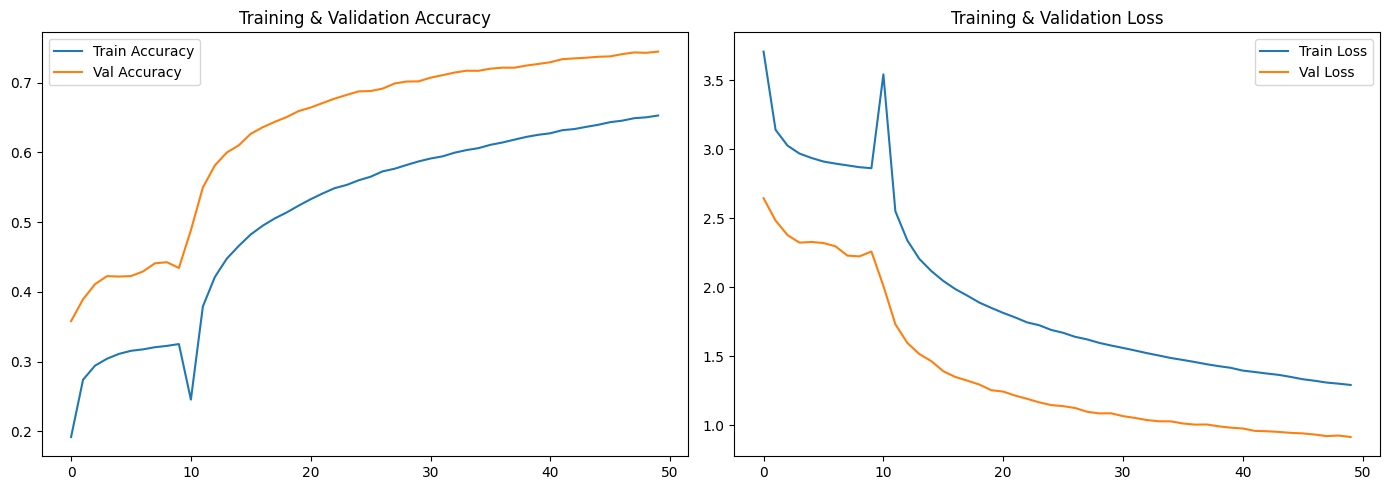

In [27]:
# --- 12. Plot Accuracy & Loss ---
acc = history.history['accuracy'] + history_fine.history['accuracy']
val_acc = history.history['val_accuracy'] + history_fine.history['val_accuracy']
loss = history.history['loss'] + history_fine.history['loss']
val_loss = history.history['val_loss'] + history_fine.history['val_loss']
epochs_range = range(total_epochs)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Train Accuracy')
plt.plot(epochs_range, val_acc, label='Val Accuracy')
plt.legend()
plt.title("Training & Validation Accuracy")

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Train Loss')
plt.plot(epochs_range, val_loss, label='Val Loss')
plt.legend()
plt.title("Training & Validation Loss")
plt.tight_layout()
plt.show()
